# Análisis de Factibilidad — Predicción de Costos Médicos

**Caso:** Aseguradora de salud privada · estimación de costos anuales de atención médica (charges).

**Objetivo del notebook:** evidenciar los hallazgos (técnicos, éticos y financieros) que sustentan la presentación. Todos los números y gráficos de la presentación deben salir de este análisis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('graficos', exist_ok=True)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv("insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [4]:
len(df)

1338

## Sesgos básicos

In [5]:
print("Distribución por genero")
df['sex'].value_counts()

Distribución por genero


sex
male      676
female    662
Name: count, dtype: int64

In [6]:
print("Costo promedio por GÉNERO")
df.groupby('sex')['charges'].mean()

Costo promedio por GÉNERO


sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64

In [7]:
print("Distribución por fumador")
df['smoker'].value_counts()

Distribución por fumador


smoker
no     1064
yes     274
Name: count, dtype: int64

In [8]:
print("Costo promedio POR FUMADOR")
df.groupby('smoker')['charges'].mean()

Costo promedio POR FUMADOR


smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

In [9]:
print("Distribución de edades")
df["age"].value_counts().sort_index()

Distribución de edades


age
18    69
19    68
20    29
21    28
22    28
23    28
24    28
25    28
26    28
27    28
28    28
29    27
30    27
31    27
32    26
33    26
34    26
35    25
36    25
37    25
38    25
39    25
40    27
41    27
42    27
43    27
44    27
45    29
46    29
47    29
48    29
49    28
50    29
51    29
52    29
53    28
54    28
55    26
56    26
57    26
58    25
59    25
60    23
61    23
62    23
63    23
64    22
Name: count, dtype: int64

## 1. Validación de las cifras clave (las que defienden la presentación)

In [10]:
# 1) Tabaquismo: la variable con mayor efecto sobre el costo
costo_smoker_yes = df[df['smoker'] == 'yes']['charges'].mean()
costo_smoker_no  = df[df['smoker'] == 'no' ]['charges'].mean()
print(f'Costo promedio FUMADOR: ${costo_smoker_yes:,.0f}   |   NO FUMADOR: ${costo_smoker_no:,.0f}')
print(f'-> El tabaquismo casi cuadruplica el costo promedio ({costo_smoker_yes / costo_smoker_no:.1f}x).')
print()

# 2) IMC: variable proxy de riesgo
costo_bmi_alto = df[df['bmi'] > 30]['charges'].mean()
costo_bmi_bajo = df[df['bmi'] <= 30]['charges'].mean()
print(f'Costo promedio IMC > 30: ${costo_bmi_alto:,.0f}   |   IMC <= 30: ${costo_bmi_bajo:,.0f}')
print(f'-> El IMC alto eleva el costo en un {(costo_bmi_alto / costo_bmi_bajo - 1) * 100:.0f}%.')
print()

# 3) Sexo: diferencia que SÍ existe, pero ES UN SESGO (no hay razón causal)
costo_sex_m   = df[df['sex'] == 'male']['charges'].mean()
costo_sex_f   = df[df['sex'] == 'female']['charges'].mean()
print(f'Costo promedio HOMBRES: ${costo_sex_m:,.0f}   |   MUJERES: ${costo_sex_f:,.0f}')
print(f'-> Los hombres pagan en promedio ${costo_sex_m - costo_sex_f:,.0f} más (diferencia sin causalidad demostrada).')

Costo promedio FUMADOR: $32,050   |   NO FUMADOR: $8,434
-> El tabaquismo casi cuadruplica el costo promedio (3.8x).

Costo promedio IMC > 30: $15,561   |   IMC <= 30: $10,719
-> El IMC alto eleva el costo en un 45%.

Costo promedio HOMBRES: $13,957   |   MUJERES: $12,570
-> Los hombres pagan en promedio $1,387 más (diferencia sin causalidad demostrada).


In [11]:
# Insight ético clave: el efecto del sexo se INVIERTE según tabaquismo
tabla_sexo = df.groupby(['smoker', 'sex'])['charges'].mean().round(0).unstack()
print(tabla_sexo)
print()
print('-> Entre NO fumadores, las mujeres pagan MÁS ($8.762 vs $8.087).')
print('-> Entre FUMADORES, los hombres pagan MÁS ($33.042 vs $30.679).')
print('-> Conclusión: el Sexo NO tiene un efecto estable → usarlo como feature reproduce discriminación arbitraria.')

sex      female     male
smoker                  
no       8762.0   8087.0
yes     30679.0  33042.0

-> Entre NO fumadores, las mujeres pagan MÁS ($8.762 vs $8.087).
-> Entre FUMADORES, los hombres pagan MÁS ($33.042 vs $30.679).
-> Conclusión: el Sexo NO tiene un efecto estable → usarlo como feature reproduce discriminación arbitraria.


## 2. Análisis gráfico (todos los gráficos se exportan a la carpeta `graficos/`)

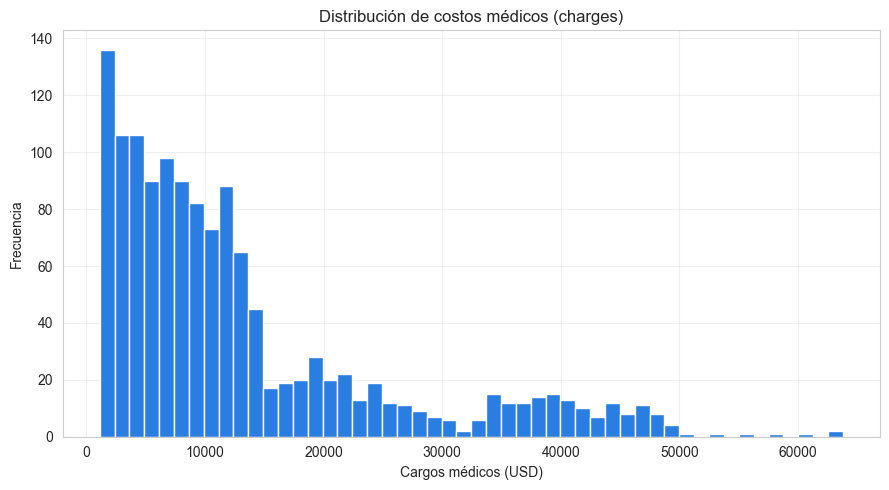

In [12]:
# Gráfico 1: distribución de los costos médicos
plt.figure()
df['charges'].hist(bins=50, edgecolor='white', color='#2a7de1')
plt.title('Distribución de costos médicos (charges)')
plt.xlabel('Cargos médicos (USD)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('graficos/histograma_charges.png', dpi=150, bbox_inches='tight')
plt.show()

<Figure size 900x500 with 0 Axes>

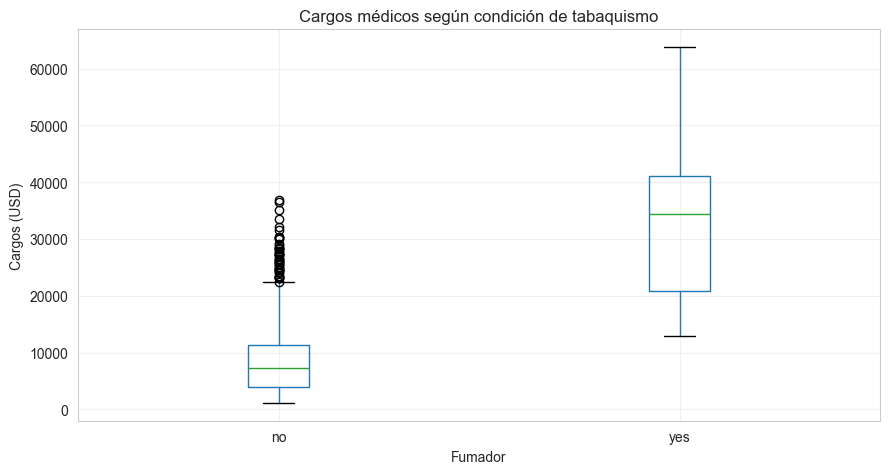

In [13]:
# Gráfico 2: boxplot por fumador
plt.figure()
df.boxplot(column='charges', by='smoker')
plt.suptitle('')
plt.title('Cargos médicos según condición de tabaquismo')
plt.xlabel('Fumador')
plt.ylabel('Cargos (USD)')
plt.tight_layout()
plt.savefig('graficos/boxplot_fumador.png', dpi=150, bbox_inches='tight')
plt.show()

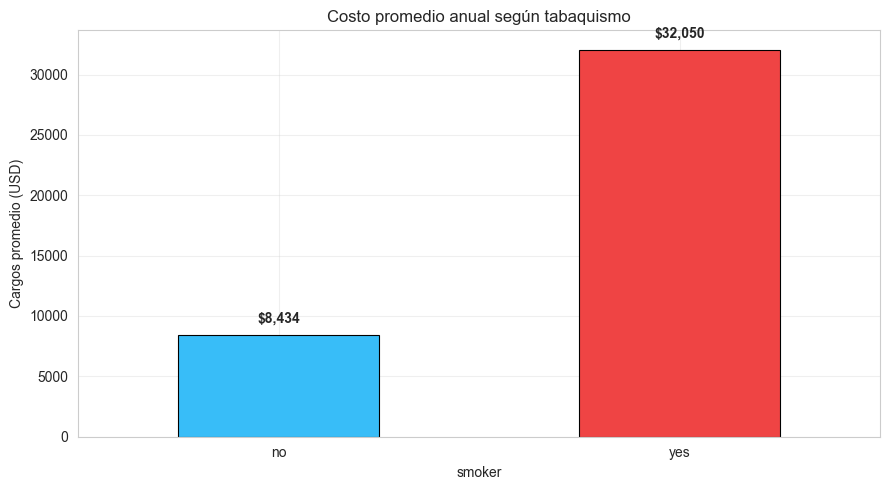

In [14]:
# Gráfico 3: GRÁFICO DE BARRAS principal — costo promedio por fumador
promedio_fumador = df.groupby('smoker')['charges'].mean().round(0)
plt.figure()
ax = promedio_fumador.plot(kind='bar', color=['#38bdf8', '#ef4444'], edgecolor='black', linewidth=0.8)
for i, v in enumerate(promedio_fumador):
    ax.text(i, v + 1000, f'${v:,.0f}', ha='center', fontweight='bold')
plt.title('Costo promedio anual según tabaquismo')
plt.ylabel('Cargos promedio (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('graficos/bar_fumador.png', dpi=150, bbox_inches='tight')
plt.show()

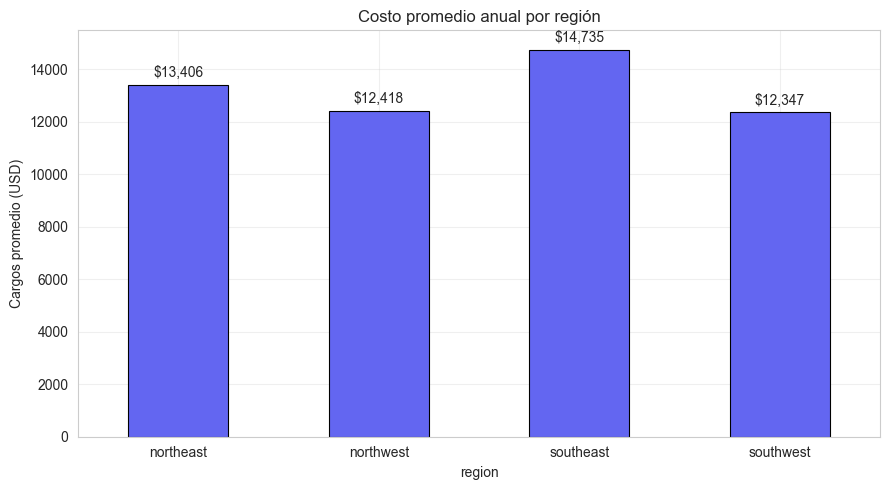

In [15]:
# Gráfico 4: costo promedio por región (variable a EXCLUIR del modelo por riesgo de sesgo)
promedio_region = df.groupby('region')['charges'].mean().round(0)
plt.figure()
ax = promedio_region.plot(kind='bar', color='#6366f1', edgecolor='black', linewidth=0.8)
for i, v in enumerate(promedio_region):
    ax.text(i, v + 300, f'${v:,.0f}', ha='center')
plt.title('Costo promedio anual por región')
plt.ylabel('Cargos promedio (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('graficos/bar_region.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Evaluación financiera: 3 alternativas (MM CLP)

Cifras anuales estimadas (millones de pesos chilenos) para un horizonte de 6 meses. Desglose según la pauta: **infraestructura cloud, licencias de software, RR.HH. y agentes/servicios automáticos**.

In [16]:
costos = pd.DataFrame({
    'A: Dashboard Descriptivo (BI)': {
        'Infraestructura cloud': 0.375,
        'Licencias de software': 1.000,
        'RR.HH.': 0.750,
        'Agentes y servicios': 0.250
    },
    'B: Modelo Predictivo (ML)': {
        'Infraestructura cloud': 2.400,
        'Licencias de software': 1.800,
        'RR.HH.': 6.600,
        'Agentes y servicios': 0.600
    },
    'C: Cumplimiento Integral': {
        'Infraestructura cloud': 8.000,
        'Licencias de software': 6.000,
        'RR.HH.': 24.000,
        'Agentes y servicios': 2.850
    }
}).T
costos['Total (MM CLP)'] = costos.sum(axis=1).round(2)
costos = costos.round(2)
print('Costos estimados (millones de CLP, aprox. 1 año):')
costos

Costos estimados (millones de CLP, aprox. 1 año):


,Infraestructura cloud,Licencias de software,RR.HH.,Agentes y servicios,Total (MM CLP)
A: Dashboard Descriptivo (BI),0.38,1.0,0.75,0.25,2.38
B: Modelo Predictivo (ML),2.40,1.8,6.60,0.60,11.40
C: Cumplimiento Integral,8.00,6.0,24.00,2.85,40.85


C:\Users\Pavillion\AppData\Local\Temp\ipykernel_17112\1758692260.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['A: BI\nDescrip.', 'B: ML\nPredictivo', 'C: Cumplimiento\nIntegral'], fontsize=9)


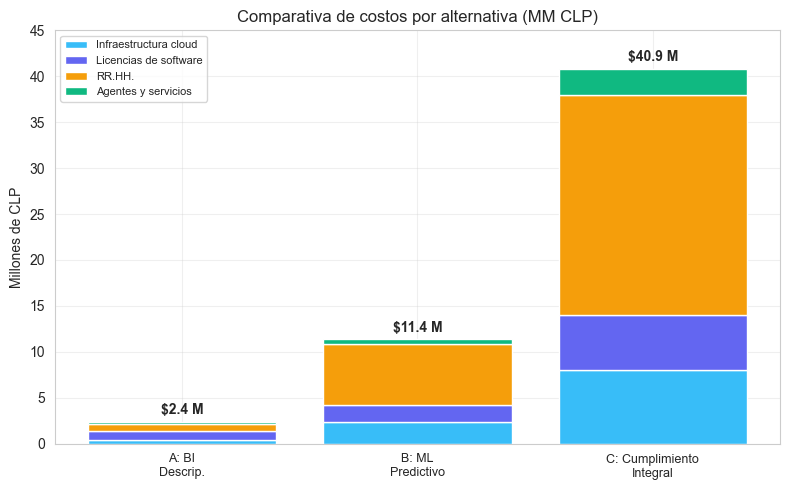

In [17]:
# Gráfico 5: barras aplanadas apiladas — comparativa de costos de las 3 alternativas
componentes = ['Infraestructura cloud', 'Licencias de software', 'RR.HH.', 'Agentes y servicios']
eticas = ['A: Dashboard Descriptivo (BI)', 'B: Modelo Predictivo (ML)', 'C: Cumplimiento Integral']
colores = ['#38bdf8', '#6366f1', '#f59e0b', '#10b981']

fig, ax = plt.subplots(figsize=(8, 5))
bottoms = np.zeros(len(eticas))
for col, color in zip(componentes, colores):
    ax.bar(eticas, costos[col], bottom=bottoms, label=col, color=color, edgecolor='white')
    bottoms += costos[col].values

for i, total in enumerate(costos['Total (MM CLP)']):
    ax.text(i, total + 0.8, f'${total:,.1f} M', ha='center', fontweight='bold')

ax.set_title('Comparativa de costos por alternativa (MM CLP)')
ax.set_ylabel('Millones de CLP')
ax.legend(loc='upper left', fontsize=8)
ax.set_ylim(0, 45)
ax.set_xticklabels(['A: BI\nDescrip.', 'B: ML\nPredictivo', 'C: Cumplimiento\nIntegral'], fontsize=9)
plt.tight_layout()
plt.savefig('graficos/bar_costos_alternativas.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Timeline de implementación (6 meses)

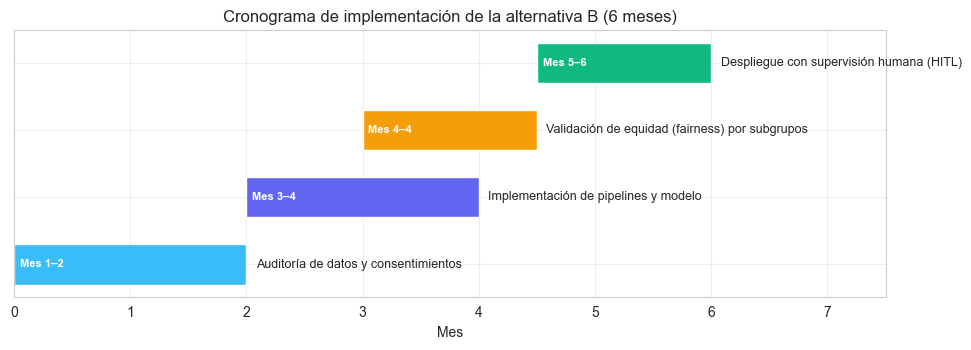

In [18]:
tareas = [
    ('Auditoría de datos y consentimientos', 0, 2, '#38bdf8'),
    ('Implementación de pipelines y modelo', 2, 2, '#6366f1'),
    ('Validación de equidad (fairness) por subgrupos', 3, 1.5, '#f59e0b'),
    ('Despliegue con supervisión humana (HITL)', 4.5, 1.5, '#10b981'),
]

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (tarea, inicio, duracion, color) in enumerate(tareas):
    ax.barh(i, duracion, left=inicio, color=color, edgecolor='white', height=0.6)
    ax.text(inicio + duracion + 0.08, i, tarea, va='center', fontsize=9)
    ax.text(inicio + 0.05, i, f'Mes {int(inicio) + 1}–{int(inicio + duracion)}', va='center', fontsize=8, color='white', fontweight='bold')

ax.set_yticks(range(len(tareas)))
ax.set_yticklabels([''] * len(tareas))
ax.set_xlim(0, 7.5)
ax.set_xlabel('Mes')
ax.set_title('Cronograma de implementación de la alternativa B (6 meses)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('graficos/timeline.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Síntesis y recomendación

**Recomendación:** Alternativa **B — Modelo Predictivo (ML)** con condiciones:

1. Excluir `sex` y `region` de las features decisivas del modelo.
2. Auditar métricas de equidad (fairness) por subgrupos.
3. Revisión humana (human-in-the-loop) para cotizaciones atípicamente altas.

**Justificación financiera:** la alternativa A resuelve visibilidad pero **no automatiza**; la C garantiza gobernanza total pero presenta **presupuesto prohibitivo** ($40.85 M vs $11.4 M). La B concentra el mayor valor por peso invertido.

In [19]:
# Resultado de respaldo para la defensa
print('El tabaquismo cuadríplica el costo promedio de atención (' + str(round(costo_smoker_yes / costo_smoker_no, 1)) + 'x).')
print('El IMC alto (>30) eleva el costo en un ' + str(round((costo_bmi_alto / costo_bmi_bajo - 1) * 100)) + '%.')
print('La diferencia por sexo no es estable entre subgrupos → se excluye como feature (' + str(round(costo_sex_m - costo_sex_f)) + ' USD en crudo).')
print()
print('Costos en MM CLP:  A=$' + str(costos.loc['A: Dashboard Descriptivo (BI)', 'Total (MM CLP)']) +
      '  B=$' + str(costos.loc['B: Modelo Predictivo (ML)', 'Total (MM CLP)']) +
      '  C=$' + str(costos.loc['C: Cumplimiento Integral', 'Total (MM CLP)']))
print('Alternativa seleccionada: B (Modelo Predictivo) con condiciones de equidad y supervisión humana.')

El tabaquismo cuadríplica el costo promedio de atención (3.8x).
El IMC alto (>30) eleva el costo en un 45%.
La diferencia por sexo no es estable entre subgrupos → se excluye como feature (1387 USD en crudo).

Costos en MM CLP:  A=$2.38  B=$11.4  C=$40.85
Alternativa seleccionada: B (Modelo Predictivo) con condiciones de equidad y supervisión humana.
